In [17]:
from SyntheticData.simulate_data import simulate_competing_risks

import pandas as pd
import numpy as np

import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold
import random
import os
from sksurv.metrics import integrated_brier_score
from pycox.evaluation import EvalSurv
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from sksurv.nonparametric import kaplan_meier_estimator
from typing import Optional, Tuple


# Data Used

In [18]:
df_synthetic, true_beta_event1, true_beta_event2 = simulate_competing_risks(n_samples=6000, seed=42,baseline_hazard_event1=0.01, baseline_hazard_event2=0.05,censoring_rate=0.01)

df_synthetic.head()

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,time,event,true_lp_event1,true_lp_event2
0,0.304717,-1.039984,0.750451,0.940565,-1.951035,-1.302180,1.0,1.0,0.0,1.0,1.0,0.0,15.084821,1,1.903896,-0.961819
1,0.127840,-0.316243,-0.016801,-0.853044,0.879398,0.777792,1.0,1.0,0.0,1.0,0.0,0.0,10.759874,2,0.970361,-0.329685
2,0.066031,1.127241,0.467509,-0.859292,0.368751,-0.958883,0.0,1.0,1.0,1.0,0.0,0.0,14.434709,2,-1.886839,2.073734
3,0.878450,-0.049926,-0.184862,-0.680930,1.222541,-0.154529,1.0,1.0,0.0,0.0,1.0,1.0,1.045714,2,2.396907,1.249025
4,-0.428328,-0.352134,0.532309,0.365444,0.412733,0.430821,0.0,1.0,0.0,1.0,0.0,1.0,128.513629,2,-2.304155,-1.329695


In [19]:
print(df_synthetic['event'].value_counts())

event
2    3598
1    1500
0     902
Name: count, dtype: int64


In [20]:
print(df_synthetic['true_lp_event1'].var(), df_synthetic['true_lp_event2'].var())

4.638129255958264 3.423580494411822


# Model

In [21]:
class FeatureNet(nn.Module):
    """
    Standalone subnetwork for a single covariate.
    Outputs a vector of size output_dim (one per cause).
    """
    def __init__(self, hidden_dim: int, num_hidden_layers: int, dropout: float, output_dim: int):
        super().__init__()
        layers = []
        in_dim = 1
        
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.Tanh())
            layers.append(nn.Dropout(dropout))
            in_dim = hidden_dim
            
        # Final layer outputs output_dim values (log‑risk contributions for each cause)
        layers.append(nn.Linear(hidden_dim, output_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)   # shape: [batch_size, output_dim]


class CRISPNAMBase(nn.Module):
    """
    Base CRISPNAM network for the full-risk competing risks baseline.
    
    Structure:
      input -> [FeatureNet_1, ..., FeatureNet_p] -> Additive Aggregation -> output head
    """
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int = 32,
        num_hidden_layers: int = 5,
        dropout: float = 0.2,
        output_dim: int = 1,   # Base model predicts 1 target cause at a time
    ):
        super().__init__()

        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim

        # Instantiate a standalone FeatureNet for each input dimension
        self.feature_nets = nn.ModuleList([
            FeatureNet(hidden_dim, num_hidden_layers, dropout, output_dim) for _ in range(input_dim)
        ])
        
        # Global bias term for the additive model
        self.bias = nn.Parameter(torch.zeros(1))

        self._reset_parameters()

    def _reset_parameters(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor, return_embedding: bool = False) -> torch.Tensor | Tuple[torch.Tensor, torch.Tensor]:
        """
        Integrated Model Flow
        """
        feature_outputs = []
        
        # Pass each individual feature through its dedicated FeatureNet
        for i in range(self.input_dim):
            # Extract single feature, reshape to [batch_size, 1]
            feat = x[:, i].unsqueeze(1)
            out = self.feature_nets[i](feat) 
            feature_outputs.append(out)
            
        # Stack into shape: [batch_size, input_dim, 1]
        stacked_outputs = torch.stack(feature_outputs, dim=1)
        
        # Additive aggregation: Sum across the feature dimension
        # Shape becomes [batch_size, 1]
        risk_score = stacked_outputs.sum(dim=1) + self.bias
        
        if return_embedding:
            # Return the final score and the matrix of individual feature contributions
            return risk_score, stacked_outputs
        return risk_score
    
    def compute_baseline_subdistribution_hazards(self, train_loader,cause= 1, device="cuda"):
        """
        Computes the baseline subdistribution hazards for Cause 1 
        using Breslow-type estimator logic for the Fine-Gray model.
        """
        self.eval()
        all_times = []
        all_events = []
        all_risks = []
        
        with torch.no_grad():
            for batch_x, batch_t, batch_e in train_loader:
                batch_x = batch_x.to(device)
                risk_scores = self.forward(batch_x).cpu().numpy().flatten()
                
                all_times.extend(batch_t.numpy())
                all_events.extend(batch_e.numpy())
                all_risks.extend(np.exp(risk_scores)) # Convert log-risk to hazard ratio
                
        times = np.array(all_times)
        events = np.array(all_events)
        risks = np.array(all_risks)
        
        # Sort everything by time
        idx = np.argsort(times)
        times, events, risks = times[idx], events[idx], risks[idx]
        
        unique_times = np.unique(times)
        baseline_hazards = []
        
        for t in unique_times:
            
            risk_set_mask = (times >= t) | ((times < t) & (events != cause) & (events != 0))
            
            # Count failures for the specified cause at this exact time
            failures = np.sum((times == t) & (events == cause))
            sum_risk = np.sum(risks[risk_set_mask])
            
            if sum_risk > 0:
                baseline_hazards.append(failures / sum_risk)
            else:
                baseline_hazards.append(0.0)
                
        # Return unique time steps and the accumulated cumulative baseline hazard
        return unique_times, np.cumsum(baseline_hazards)

    def predict_survival(self, x: torch.Tensor, times: np.ndarray, baseline_times=None, baseline_cum_hazard=None) -> torch.Tensor:
        """
        Predicts mathematically valid survival probabilities at specified time points.
        """
        log_risk = self.forward(x) 
        hazard_ratio = torch.exp(log_risk)
        
        if baseline_times is None or baseline_cum_hazard is None:
            grid_tensor = torch.tensor(times, dtype=torch.float32, device=x.device)
            cif = 1.0 - torch.exp(-hazard_ratio @ grid_tensor.unsqueeze(0) * 0.01)
        else:
            interp_hazard = np.interp(times, baseline_times, baseline_cum_hazard)
            interp_hazard_tensor = torch.tensor(interp_hazard, dtype=torch.float32, device=x.device)
            cif = 1.0 - torch.exp(-hazard_ratio @ interp_hazard_tensor.unsqueeze(0))
        
        survival_probs = 1.0 - cif
        return torch.clamp(survival_probs, 0.0, 1.0)

In [22]:
# model = CRISPNAMBase(input_dim=12,hidden_dim=32,num_hidden_layers=5,dropout=0.2,output_dim=2)

In [23]:



# -----------------------------
# 1) Full-cohort risk set helper
# -----------------------------
class RisksetSampling:
    """
    Full cohort risk set construction for Fine-Gray style competing risks.

    Base definition used here for cause k:
        j is in the risk set for event i if
        T_j >= T_i  OR  (T_j < T_i and D_j != k)

    This keeps subjects with competing events in the subdistribution risk set.
    """

    def __init__(self, cause: int = 1):
        self.cause = cause

    def build_mask(self, times: torch.Tensor, events: torch.Tensor) -> torch.Tensor:
        """
        Returns:
            risk_mask: [n, n] boolean tensor
                       risk_mask[i, j] = True if j is in risk set for i
        """
        times = times.view(-1)
        events = events.view(-1)

        t_i = times.unsqueeze(1)  # [n, 1]
        t_j = times.unsqueeze(0)  # [1, n]
        e_j = events.unsqueeze(0) # [1, n]

        # Full Fine-Gray subdistribution risk set
        risk_mask = (t_j >= t_i) | ((t_j < t_i) & (e_j != self.cause) & (e_j != 0))
        return risk_mask

    def event_indices(self, events: torch.Tensor) -> torch.Tensor:
        return torch.where(events.view(-1) == self.cause)[0]

In [24]:
class FineGrayLoss(nn.Module):
    """
    Fine‑Gray negative log‑partial likelihood for a specific cause.
    Uses the full risk set (no sampling, no IPCW, no class weights).
    """
    def __init__(self, cause: int = 1):
        super().__init__()
        self.cause = cause

    def forward(self, risk_scores: torch.Tensor, times: torch.Tensor, events: torch.Tensor) -> torch.Tensor:
        """
        Args:
            risk_scores: [N] or [N,1] predicted log‑hazard ratios for the cause.
            times:       [N] observed event times.
            events:      [N] event indicators (0=censored, 1..K=causes).
        Returns:
            scalar loss (negative average partial likelihood) for self.cause.
        """
        # Ensure risk_scores is 1D
        if risk_scores.dim() == 2 and risk_scores.shape[1] == 1:
            risk_scores = risk_scores.squeeze(1)
        elif risk_scores.dim() != 1:
            raise ValueError(f"Expected 1D or [N,1] risk_scores, got {risk_scores.shape}")

        # Indices of subjects who experienced the target cause
        event_idx = torch.where(events == self.cause)[0]
        if len(event_idx) == 0:
            return torch.tensor(0.0, device=risk_scores.device, requires_grad=True)

        # Build risk set mask for the target cause
        sampler = RisksetSampling(cause=self.cause)
        risk_mask = sampler.build_mask(times, events)   # [N, N]

        # Extract rows for events of this cause
        risk_mask_events = risk_mask[event_idx]         # [n_events, N]

        loss_k = 0.0
        for i, idx in enumerate(event_idx):
            mask = risk_mask_events[i]
            denom = torch.logsumexp(risk_scores[mask], dim=0)
            loss_k += risk_scores[idx] - denom

        return -loss_k / len(event_idx)

In [25]:
class BatchFineGrayLossSingle(nn.Module):
    def __init__(self, cause=1):
        super().__init__()
        self.cause = cause

    def forward(self, risk_scores, times, events):
        # risk_scores: [batch_size] (scalar per subject)
        # times: [batch_size]
        # events: [batch_size]
        batch_size = risk_scores.shape[0]
        event_idx = torch.where(events == self.cause)[0]
        if len(event_idx) == 0:
            return torch.tensor(0.0, device=risk_scores.device, requires_grad=True)

        t_i = times[event_idx].unsqueeze(1)  # [n_events, 1]
        t_j = times.unsqueeze(0)             # [1, batch_size]
        e_j = events.unsqueeze(0)            # [1, batch_size]

        # Risk set mask for batch (approximation!)
        risk_mask = (t_j >= t_i) | (e_j != self.cause)

        loss = 0.0
        for idx, i in enumerate(event_idx):
            mask = risk_mask[idx]
            if mask.any():
                denom = torch.logsumexp(risk_scores[mask], dim=0)
                loss += risk_scores[i] - denom
        return -loss / len(event_idx)

In [26]:

# -----------------------------
# 3) Early stopping utility
# -----------------------------
class EarlyStopping:
    def __init__(self, patience: int = 10, min_delta: float = 0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.best_state = None
        self.should_stop = False

    def step(self, val_loss: float, model: nn.Module):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True


In [27]:
def train_model_minibatch(
    model,
    optimizer,
    train_loader,
    val_loader,
    criterion,
    num_epochs=100,
    patience=10,
    device="cuda"
):
    model = model.to(device)
    stopper = EarlyStopping(patience=patience)
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(num_epochs):
        # ---- Training ----
        model.train()
        train_loss = 0.0
        num_batches = 0
        for batch_x, batch_t, batch_e in train_loader:
            batch_x, batch_t, batch_e = batch_x.to(device), batch_t.to(device), batch_e.to(device)
            optimizer.zero_grad()
            preds = model(batch_x).squeeze(-1)   # [batch_size]
            loss = criterion(preds, batch_t, batch_e)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            num_batches += 1
        avg_train_loss = train_loss / num_batches

        # ---- Validation ----
        model.eval()
        val_loss = 0.0
        num_val_batches = 0
        with torch.no_grad():
            for batch_x, batch_t, batch_e in val_loader:
                batch_x, batch_t, batch_e = batch_x.to(device), batch_t.to(device), batch_e.to(device)
                preds = model(batch_x).squeeze(-1)
                loss = criterion(preds, batch_t, batch_e)
                val_loss += loss.item()
                num_val_batches += 1
        avg_val_loss = val_loss / num_val_batches

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        print(f"Epoch {epoch+1:03d} | train_loss={avg_train_loss:.4f} | val_loss={avg_val_loss:.4f}")

        stopper.step(avg_val_loss, model)
        if stopper.should_stop:
            break

    if stopper.best_state is not None:
        model.load_state_dict(stopper.best_state)
    return model, history

In [28]:
def _collect_full_cohort(loader, device):
    xs, ts, es = [], [], []
    for batch in loader:
        x, t, e = batch[:3]
        xs.append(x.to(device))
        ts.append(t.to(device))
        es.append(e.to(device))
    return torch.cat(xs, dim=0), torch.cat(ts, dim=0), torch.cat(es, dim=0)

def train_model_full_cohort(
    model,
    optimizer,
    train_loader,
    val_loader,
    criterion,            # the FineGrayLoss defined above
    num_epochs: int = 100,
    patience: int = 10,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",
):
    model = model.to(device)
    stopper = EarlyStopping(patience=patience)

    # Collect full training data once (no batching inside loop)
    train_x, train_t, train_e = _collect_full_cohort(train_loader, device)
    # Collect full validation data once (for loss computation)
    val_x, val_t, val_e = _collect_full_cohort(val_loader, device)

    history = {"train_loss": [], "val_loss": []}

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()
        preds = model(train_x)                     # [N_train, K]
        loss = criterion(preds, train_t, train_e)
        loss.backward()
        optimizer.step()
        train_loss_val = loss.item()

        # Validation
        model.eval()
        with torch.no_grad():
            val_preds = model(val_x)               # [N_val, K]
            val_loss = criterion(val_preds, val_t, val_e)
        val_loss_val = val_loss.item()

        history["train_loss"].append(train_loss_val)
        history["val_loss"].append(val_loss_val)

        print(f"Epoch {epoch+1:03d}/{num_epochs} | train_loss={train_loss_val:.6f} | val_loss={val_loss_val:.6f}")

        stopper.step(val_loss_val, model)
        if stopper.should_stop:
            print(f"Early stopping at epoch {epoch+1}.")
            break

    if stopper.best_state is not None:
        model.load_state_dict(stopper.best_state)

    return model, history

In [29]:
def train_model_5fold_full_cohort(
    build_model_fn,
    X,
    times,
    events,
    batch_size: int = 256,   # only used for DataLoader, but training will collect all
    num_epochs: int = 100,
    patience: int = 10,
    k_folds: int = 5,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,   # L2 regularization via Adam
    cause: int = 1,               
    seed: int = 42,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",
):
    X_np = X.values if hasattr(X, 'values') else np.array(X)
    times_np = times.values if hasattr(times, 'values') else np.array(times)
    events_np = events.values if hasattr(events, 'values') else np.array(events)

    X_tensor = torch.tensor(X_np, dtype=torch.float32)
    times_tensor = torch.tensor(times_np, dtype=torch.float32)
    events_tensor = torch.tensor(events_np, dtype=torch.long)

    kf = KFold(n_splits=k_folds, shuffle=True, random_state=seed)

    criterion = FineGrayLoss(cause=cause)   # base loss, no gamma

    fold_histories = []
    fold_models = []
    fold_ibs_scores = []
    fold_cindex_scores = []
    all_test_predictions = []
    all_test_indices = []
    all_true_times = []
    all_true_events = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_tensor), start=1):
        print(f"\n===== Fold {fold}/{k_folds} =====")

        X_train, X_val = X_tensor[train_idx], X_tensor[val_idx]
        t_train, t_val = times_tensor[train_idx], times_tensor[val_idx]
        e_train, e_val = events_tensor[train_idx], events_tensor[val_idx]

        train_ds = TensorDataset(X_train, t_train, e_train)
        val_ds = TensorDataset(X_val, t_val, e_val)

        # DataLoaders still used for _collect_full_cohort
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False)
        val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

        model = build_model_fn().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

        model, history = train_model_full_cohort(
            model=model,
            optimizer=optimizer,
            train_loader=train_loader,
            val_loader=val_loader,
            criterion=criterion,
            num_epochs=num_epochs,
            patience=patience,
            device=device,
        )

        # ---- Evaluation (same as before) ----
        model.eval()
        time_grid = np.percentile(times_np[val_idx], np.linspace(5, 99, 100))
        with torch.no_grad():
            base_times, cum_hazard = model.compute_baseline_subdistribution_hazards(train_loader, cause=cause, device=device)
            val_preds = model.predict_survival(X_val.to(device), times=time_grid,
                                               baseline_times=base_times, baseline_cum_hazard=cum_hazard)
            val_preds = val_preds.cpu().numpy()

            all_test_predictions.append(val_preds)
            all_test_indices.append(val_idx)
            all_true_times.append(times_np[val_idx])
            all_true_events.append(events_np[val_idx])

            # Pycox evaluation
            if val_preds.shape[0] != len(time_grid):
                val_preds_df = pd.DataFrame(val_preds.T, index=time_grid)
            else:
                val_preds_df = pd.DataFrame(val_preds, index=time_grid)

            durations_val = times_np[val_idx]
            events_val = (events_np[val_idx] == cause).astype(int)
            ev = EvalSurv(surv=val_preds_df, durations=durations_val, events=events_val, censor_surv=None, censor_durations=None)

            # Censoring estimate from training set (for IPCW in Brier score)
            censoring_mask_train = (events_np[train_idx] == 0)
            time_cens, prob_cens = kaplan_meier_estimator(censoring_mask_train, times_np[train_idx])
            prob_cens = np.clip(prob_cens, 1e-8, 1.0)
            if time_cens[0] > 0:
                time_cens = np.insert(time_cens, 0, 0.0)
                prob_cens = np.insert(prob_cens, 0, 1.0)
            prob_cens_2d = np.tile(prob_cens[:, np.newaxis], (1, len(val_idx)))
            censor_surv_2d = pd.DataFrame(prob_cens_2d, index=time_cens, columns=val_preds_df.columns)
            ev.add_censor_est(censor_surv_2d)

            score_ibs = ev.integrated_brier_score(time_grid)
            score_c_idx = ev.concordance_td('antolini')
            fold_ibs_scores.append(score_ibs)
            fold_cindex_scores.append(score_c_idx)
            print(f"Fold {fold} | IBS: {score_ibs:.4f} | C-Index: {score_c_idx:.4f}")

        fold_models.append(model)
        fold_histories.append(history)

    print(f"\n===== CV Complete =====")
    print(f"Mean C-index: {np.mean(fold_cindex_scores):.4f} +/- {np.std(fold_cindex_scores):.4f}")
    print(f"Mean IBS: {np.mean(fold_ibs_scores):.4f} +/- {np.std(fold_ibs_scores):.4f}")

    return fold_models, fold_histories, fold_ibs_scores, fold_cindex_scores, all_test_predictions, all_test_indices, all_true_times, all_true_events

In [30]:
def train_model_5fold_full_cohort_minibatch_training(
    build_model_fn,
    X,
    times,
    events,
    batch_size: int = 256,   # only used for DataLoader, but training will collect all
    num_epochs: int = 100,
    patience: int = 10,
    k_folds: int = 5,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,   # L2 regularization via Adam
    cause: int = 1,               
    seed: int = 42,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",
):
    X_np = X.values if hasattr(X, 'values') else np.array(X)
    times_np = times.values if hasattr(times, 'values') else np.array(times)
    events_np = events.values if hasattr(events, 'values') else np.array(events)

    X_tensor = torch.tensor(X_np, dtype=torch.float32)
    times_tensor = torch.tensor(times_np, dtype=torch.float32)
    events_tensor = torch.tensor(events_np, dtype=torch.long)

    kf = KFold(n_splits=k_folds, shuffle=True, random_state=seed)

    criterion = BatchFineGrayLossSingle(cause=cause)

    fold_histories = []
    fold_models = []
    fold_ibs_scores = []
    fold_cindex_scores = []
    all_test_predictions = []
    all_test_indices = []
    all_true_times = []
    all_true_events = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_tensor), start=1):
        print(f"\n===== Fold {fold}/{k_folds} =====")

        X_train, X_val = X_tensor[train_idx], X_tensor[val_idx]
        t_train, t_val = times_tensor[train_idx], times_tensor[val_idx]
        e_train, e_val = events_tensor[train_idx], events_tensor[val_idx]

        train_ds = TensorDataset(X_train, t_train, e_train)
        val_ds = TensorDataset(X_val, t_val, e_val)

        # DataLoaders still used for _collect_full_cohort
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False)
        val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

        model = build_model_fn().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

        model, history = train_model_minibatch(
            model=model,
            optimizer=optimizer,
            train_loader=train_loader,
            val_loader=val_loader,
            criterion=criterion,
            num_epochs=num_epochs,
            patience=patience,
            device=device,
        )

        # ---- Evaluation (same as before) ----
        model.eval()
        time_grid = np.percentile(times_np[val_idx], np.linspace(5, 99, 100))
        with torch.no_grad():
            base_times, cum_hazard = model.compute_baseline_subdistribution_hazards(train_loader, cause=cause, device=device)
            val_preds = model.predict_survival(X_val.to(device), times=time_grid,
                                               baseline_times=base_times, baseline_cum_hazard=cum_hazard)
            val_preds = val_preds.cpu().numpy()

            all_test_predictions.append(val_preds)
            all_test_indices.append(val_idx)
            all_true_times.append(times_np[val_idx])
            all_true_events.append(events_np[val_idx])

            # Pycox evaluation
            if val_preds.shape[0] != len(time_grid):
                val_preds_df = pd.DataFrame(val_preds.T, index=time_grid)
            else:
                val_preds_df = pd.DataFrame(val_preds, index=time_grid)

            durations_val = times_np[val_idx]
            events_val = (events_np[val_idx] == cause).astype(int)
            ev = EvalSurv(surv=val_preds_df, durations=durations_val, events=events_val, censor_surv=None, censor_durations=None)

            # Censoring estimate from training set (for IPCW in Brier score)
            censoring_mask_train = (events_np[train_idx] == 0)
            time_cens, prob_cens = kaplan_meier_estimator(censoring_mask_train, times_np[train_idx])
            prob_cens = np.clip(prob_cens, 1e-8, 1.0)
            if time_cens[0] > 0:
                time_cens = np.insert(time_cens, 0, 0.0)
                prob_cens = np.insert(prob_cens, 0, 1.0)
            prob_cens_2d = np.tile(prob_cens[:, np.newaxis], (1, len(val_idx)))
            censor_surv_2d = pd.DataFrame(prob_cens_2d, index=time_cens, columns=val_preds_df.columns)
            ev.add_censor_est(censor_surv_2d)

            score_ibs = ev.integrated_brier_score(time_grid)
            score_c_idx = ev.concordance_td('antolini')
            fold_ibs_scores.append(score_ibs)
            fold_cindex_scores.append(score_c_idx)
            print(f"Fold {fold} | IBS: {score_ibs:.4f} | C-Index: {score_c_idx:.4f}")

        fold_models.append(model)
        fold_histories.append(history)

    print(f"\n===== CV Complete =====")
    print(f"Mean C-index: {np.mean(fold_cindex_scores):.4f} +/- {np.std(fold_cindex_scores):.4f}")
    print(f"Mean IBS: {np.mean(fold_ibs_scores):.4f} +/- {np.std(fold_ibs_scores):.4f}")

    return fold_models, fold_histories, fold_ibs_scores, fold_cindex_scores, all_test_predictions, all_test_indices, all_true_times, all_true_events

In [31]:


def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # if you are using multi-GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"


In [32]:

set_seed(42)
# Example model builder
def build_model():
    return CRISPNAMBase(
        input_dim=12,
        hidden_dim=32,
        num_hidden_layers=5,
        dropout=0.2,
        output_dim=1
    )

df = df_synthetic

models, histories, ibs_scores, cindex_scores, all_test_predictions, all_test_indices, all_true_times, all_true_events = train_model_5fold_full_cohort(
    build_model_fn=build_model,
    X=df.drop(['time', 'event','true_lp_event1','true_lp_event2'], axis=1),
    times=df['time'],
    events=df['event'],
    batch_size=1000,      # still used for DataLoader, but training collects all
    num_epochs=400,
    patience=20,
    k_folds=5,
    lr=1e-3,
    weight_decay=1e-4,    # L2 regularization via Adam
    cause=2
)

# models, histories, ibs_scores, cindex_scores, all_test_predictions, all_test_indices, all_true_times, all_true_events = train_model_5fold_full_cohort_minibatch_training(
#     build_model_fn=build_model,
#     X=df.drop(['time', 'event','true_lp_event1','true_lp_event2'], axis=1),
#     times=df['time'],
#     events=df['event'],
#     batch_size=1000,      # still used for DataLoader, but training collects all
#     num_epochs=400,
#     patience=20,
#     k_folds=5,
#     lr=1e-3,
#     weight_decay=1e-4,    # L2 regularization via Adam
#     cause=2
# )


===== Fold 1/5 =====
Epoch 001/400 | train_loss=8.486940 | val_loss=6.525304
Epoch 002/400 | train_loss=8.282985 | val_loss=6.365953
Epoch 003/400 | train_loss=8.159137 | val_loss=6.262667
Epoch 004/400 | train_loss=8.018360 | val_loss=6.192626
Epoch 005/400 | train_loss=7.954923 | val_loss=6.147161
Epoch 006/400 | train_loss=7.920800 | val_loss=6.122277
Epoch 007/400 | train_loss=7.866142 | val_loss=6.113070
Epoch 008/400 | train_loss=7.824838 | val_loss=6.114476
Epoch 009/400 | train_loss=7.823553 | val_loss=6.123183
Epoch 010/400 | train_loss=7.800503 | val_loss=6.135609
Epoch 011/400 | train_loss=7.809244 | val_loss=6.146891
Epoch 012/400 | train_loss=7.802802 | val_loss=6.155737
Epoch 013/400 | train_loss=7.762688 | val_loss=6.160513
Epoch 014/400 | train_loss=7.760824 | val_loss=6.161765
Epoch 015/400 | train_loss=7.753783 | val_loss=6.159663
Epoch 016/400 | train_loss=7.757443 | val_loss=6.154939
Epoch 017/400 | train_loss=7.733533 | val_loss=6.148621
Epoch 018/400 | train_loss

KeyboardInterrupt: 

In [ ]:
histories

[{'train_loss': [7.114013957977295,
   6.436391067504883,
   6.1967370986938475,
   6.126726341247559,
   6.1670997619628904,
   6.062418270111084,
   6.065133094787598,
   6.057365417480469,
   6.018836116790771,
   6.04669713973999,
   6.030183124542236,
   6.010845088958741,
   6.0202960014343265,
   5.988571071624756,
   5.987664985656738,
   5.975799083709717,
   5.9838567733764645,
   5.9669393539428714,
   5.94852466583252,
   5.954077053070068,
   5.950731563568115,
   5.958241081237793,
   5.931103134155274,
   5.939445877075196,
   5.922913360595703,
   5.962763977050781,
   5.938134956359863,
   5.961880397796631,
   5.922627067565918,
   5.904573249816894,
   5.952962589263916,
   5.914809894561768,
   5.914573669433594,
   5.919110488891602,
   5.932893562316894,
   5.939866447448731,
   5.90121898651123,
   5.89867935180664,
   5.885094070434571,
   5.903830242156983,
   5.890360164642334,
   5.925313472747803,
   5.8842870712280275,
   5.910914325714112,
   5.93502168655

In [ ]:
ibs_scores

[0.20972895332351071,
 0.18976586103032858,
 0.2008641150676261,
 0.214071468855318,
 0.2149555232746792]

In [ ]:
cindex_scores

[0.8540358868951725,
 0.8584624957574386,
 0.8531704347732403,
 0.8684027261922448,
 0.8505581147635494]

# Evaluation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pycox.evaluation import EvalSurv
from sksurv.nonparametric import kaplan_meier_estimator
from scipy.stats import spearmanr, pearsonr

def evaluate_and_compare_truth(
    all_test_predictions,
    all_test_indices,
    all_true_times,
    all_true_events,
    true_lp_1=None,
    true_lp_2=None,
    cause=1,
):
    """
    Evaluates pooled OOF predictions and compares them against true linear predictors.
    """
    # ---------------------------------------------------------
    # 1. Rebuild full patient cohort
    # ---------------------------------------------------------
    times = np.concatenate(all_true_times)
    events = np.concatenate(all_true_events)
    indices = np.concatenate(all_test_indices)

    n = indices.max() + 1
    full_times = np.zeros(n)
    full_events = np.zeros(n)
    full_times[indices] = times
    full_events[indices] = events

    # Define common evaluation grid
    common_grid = np.percentile(full_times, np.linspace(5, 99, 100))
    pooled = np.full((len(common_grid), n), np.nan)

    # ---------------------------------------------------------
    # 2. Insert and Interpolate Fold Predictions
    # ---------------------------------------------------------
    for fold_pred, fold_idx, fold_times in zip(
        all_test_predictions, all_test_indices, all_true_times
    ):
        pred = np.asarray(fold_pred)

        # Ensure [time x patient] shape
        if pred.shape[1] == len(fold_idx):
            pass
        elif pred.shape[0] == len(fold_idx):
            pred = pred.T
        else:
            raise ValueError(f"Cannot interpret prediction shape {pred.shape}")

        # Reconstruct fold-specific grid
        fold_grid = np.percentile(fold_times, np.linspace(5, 99, pred.shape[0]))

        # Interpolate onto common grid
        interp = np.zeros((len(common_grid), pred.shape[1]))
        for j in range(pred.shape[1]):
            interp[:, j] = np.interp(
                common_grid, fold_grid, pred[:, j], 
                left=pred[0, j], right=pred[-1, j]
            )
        pooled[:, fold_idx] = interp

    if np.isnan(pooled).any():
        raise ValueError("Missing pooled predictions in OOF aggregation.")

    # ---------------------------------------------------------
    # 3. Calculate Metrics
    # ---------------------------------------------------------
    surv_df = pd.DataFrame(pooled, index=common_grid)
    events_binary = (full_events == cause).astype(int)
    
    ev = EvalSurv(surv_df, durations=full_times, events=events_binary)

    # Censor estimate (IPCW)
    censor_mask = (full_events == 0)
    t_cens, p_cens = kaplan_meier_estimator(censor_mask, full_times)
    p_cens = np.clip(p_cens, 1e-8, 1)

    if t_cens[0] > 0:
        t_cens = np.insert(t_cens, 0, 0)
        p_cens = np.insert(p_cens, 0, 1)

    censor_df = pd.DataFrame(
        np.tile(p_cens[:, None], (1, n)),
        index=t_cens,
        columns=surv_df.columns
    )
    ev.add_censor_est(censor_df)

    eval_grid = np.asarray(common_grid, dtype=np.float64)
    c_index = ev.concordance_td("antolini")
    ibs_score = ev.integrated_brier_score(eval_grid)

    # Median Brier Score
    median_time = np.median(full_times)
    closest = eval_grid[np.abs(eval_grid - median_time).argmin()]
    normal_brier_score = float(ev.brier_score(np.array([closest])).iloc[0])

    print("\n===== POOLED OOF RESULTS =====")
    print(f"C-index: {c_index:.4f}")
    print(f"IBS: {ibs_score:.4f}")
    print(f"Brier: {normal_brier_score:.4f}")

    # ---------------------------------------------------------
    # 4. Truth Comparison and Visualization
    # ---------------------------------------------------------
    median_idx = len(eval_grid) // 2
    pred_risk_at_median = 1.0 - pooled[median_idx, :]

    def plot_truth_comparison(true_lp, label, color, cmap, plot_title):
        true_lp = np.asarray(true_lp)
        s, _ = spearmanr(true_lp, pred_risk_at_median)
        p, _ = pearsonr(true_lp, pred_risk_at_median)

        print(f"\n{label} Truth Comparison")
        print(f"Spearman: {s:.4f} | Pearson: {p:.4f}")

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        
        # Scatter
        sns.scatterplot(
            x=true_lp, y=pred_risk_at_median, alpha=0.4, 
            color=color, edgecolor=None, ax=axes[0]
        )
        axes[0].set(xlabel=f"True Linear Predictor ({label})", 
                    ylabel="Pooled Risk (Median Time)", 
                    title=f"{label}: Truth vs Model\nSpearman={s:.3f}")

        # Hexbin
        hb = axes[1].hexbin(
            true_lp, pred_risk_at_median, gridsize=25, 
            cmap=cmap, mincnt=1
        )
        plt.colorbar(hb, label='Patient Density', ax=axes[1])
        axes[1].set(xlabel=f"True Linear Predictor ({label})", 
                    ylabel="Pooled Predicted Risk", 
                    title=f"{label} Space Density Map")
        
        plt.tight_layout()
        plt.show()

    if true_lp_1 is not None:
        plot_truth_comparison(true_lp_1, "Event 1", 'teal', 'viridis', "Event 1")

    if true_lp_2 is not None:
        plot_truth_comparison(true_lp_2, "Event 2", 'crimson', 'magma', "Event 2")

    return c_index, ibs_score, normal_brier_score


===== POOLED OOF RESULTS =====
C-index: 0.8566
IBS: 0.2076
Brier: 0.1030

Event 1 Truth Comparison
Spearman: 0.8696 | Pearson: 0.7332


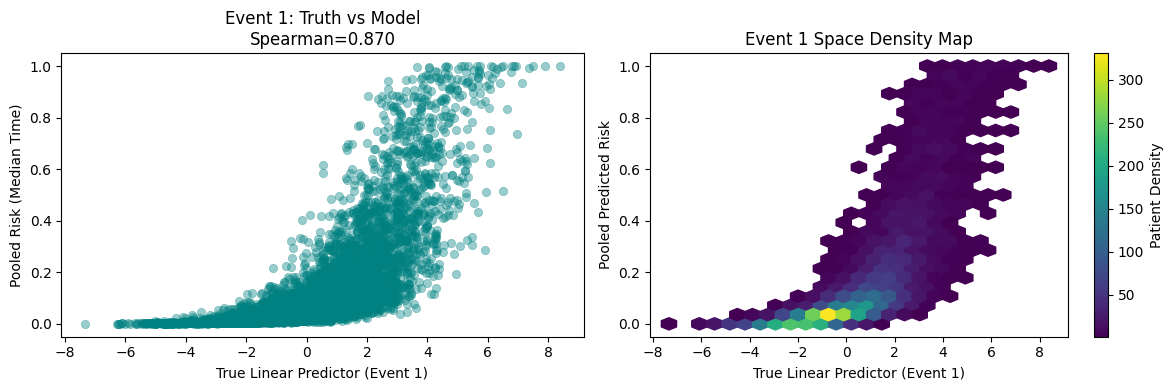


Event 2 Truth Comparison
Spearman: -0.2896 | Pearson: -0.2482


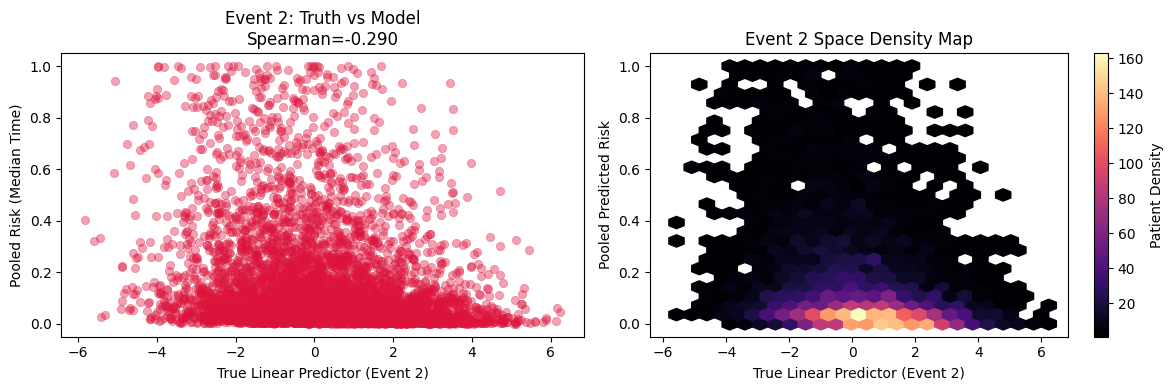

In [ ]:
c_index, ibs_score, normal_brier_score = evaluate_and_compare_truth(
    all_test_predictions=all_test_predictions,
    all_test_indices=all_test_indices,
    all_true_times=all_true_times,
    all_true_events=all_true_events,
    true_lp_1=df["true_lp_event1"].values,
    true_lp_2=df["true_lp_event2"].values,
    cause=1
)

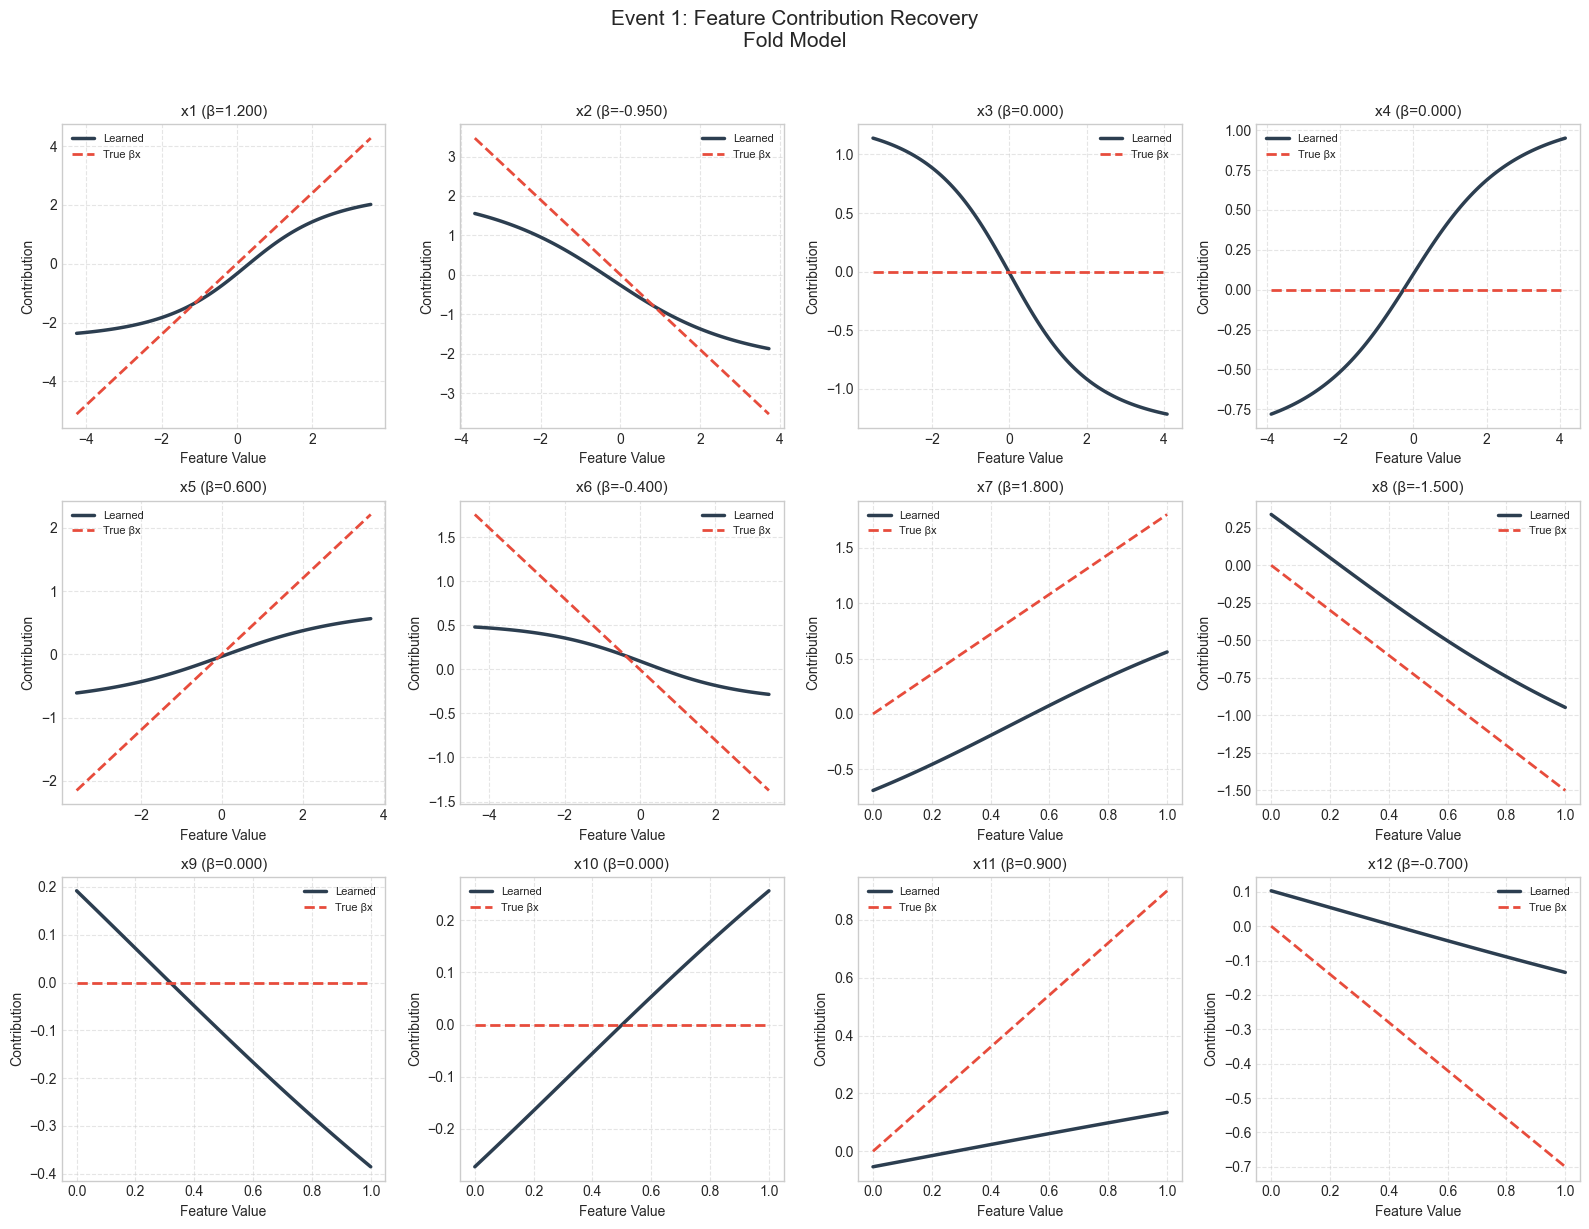

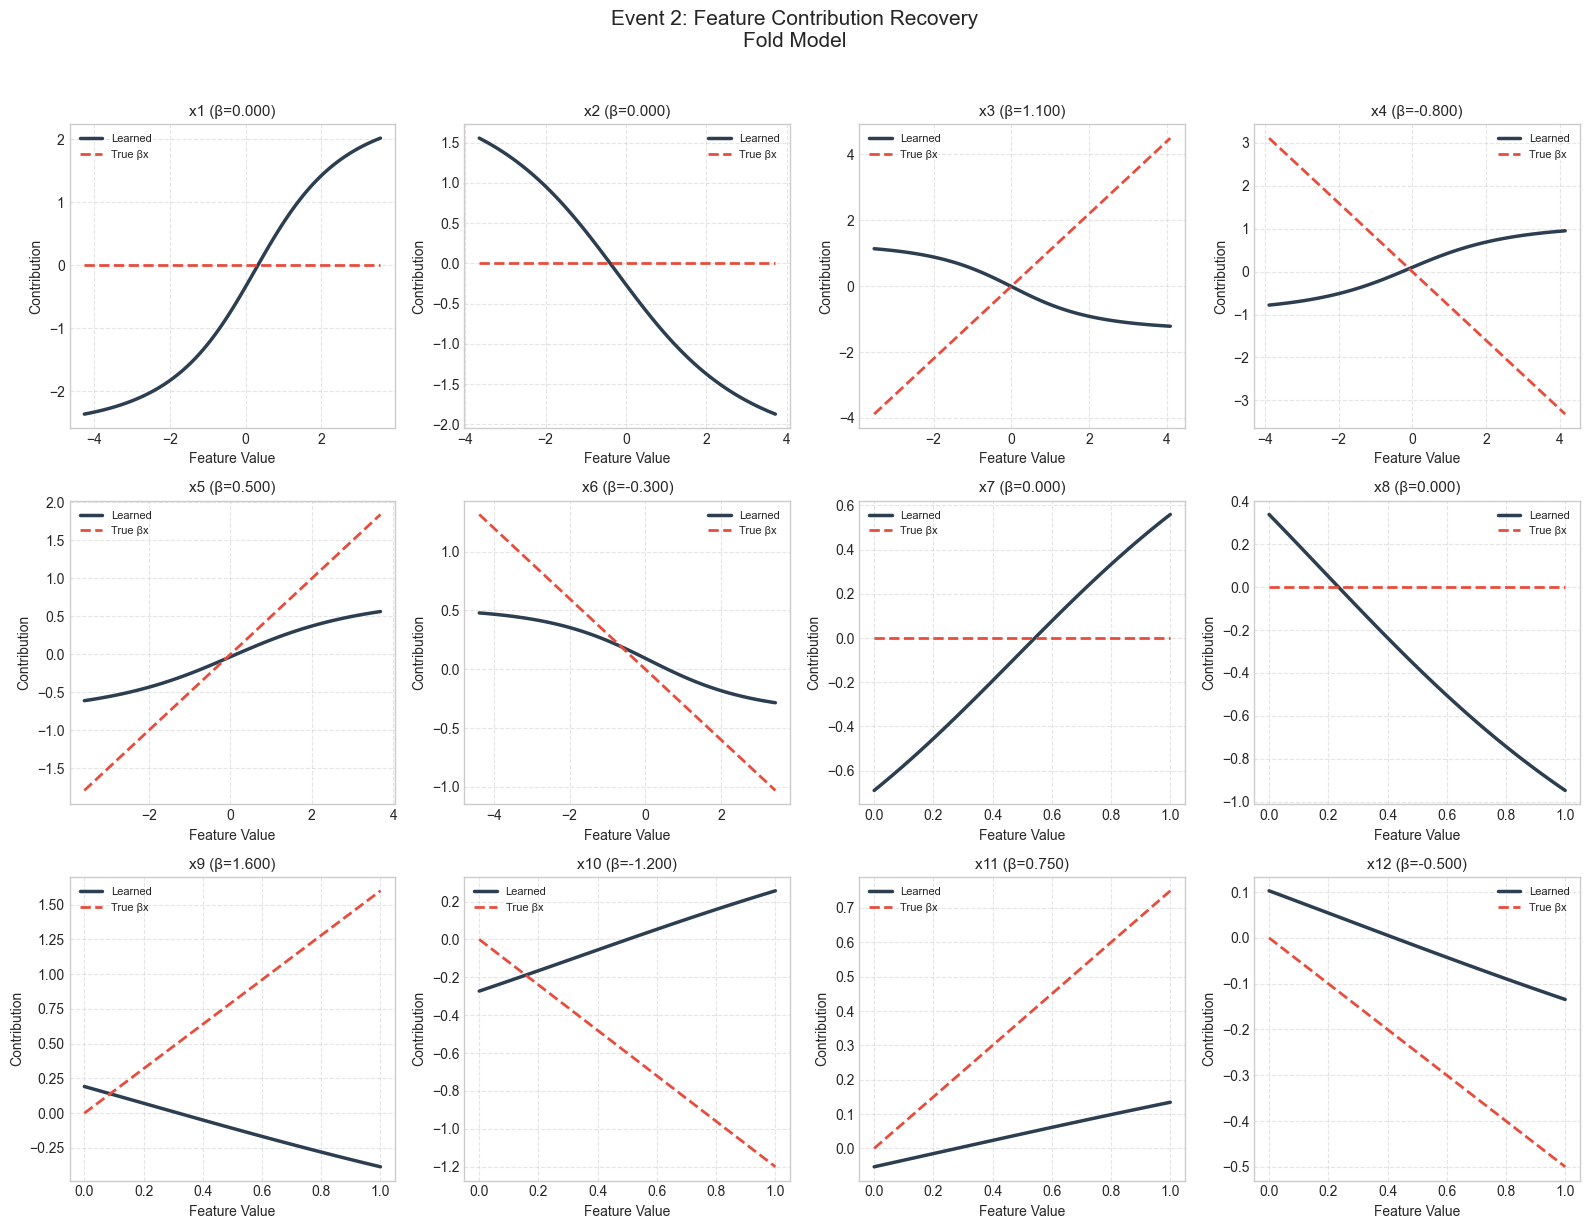

In [ ]:


from matplotlib.pyplot import grid


feature_names = df_synthetic.drop(['time', 'event', 'true_lp_event1', 'true_lp_event2'], axis=1).columns.tolist() 
data_dict = {name: df_synthetic[name] for name in feature_names}

def plot_event_contributions(
    feature_names,
    data_range_dict,
    true_betas,
    event_label,
    feature_nets,
    model_name,
    use_log=False,
    use_standardised=True,
    rows=3,
    cols=4
):

    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axes = plt.subplots(rows, cols, figsize=(16, 12))
    axes = axes.flatten()

    for i, name in enumerate(feature_names):
        ax = axes[i]

        x = np.asarray(data_range_dict[name])

        mu = x.mean()
        sigma = x.std() + 1e-8

        grid_raw = torch.linspace(x.min(), x.max(), 100).unsqueeze(1).float()

        if use_standardised:
            grid_model = (grid_raw - mu) / sigma
            x_plot = (grid_raw.numpy().flatten() - mu) / sigma
            xlabel = "Standardised Feature (z-score)"
        else:
            grid_model = grid_raw
            x_plot = grid_raw.numpy().flatten()
            xlabel = "Feature Value"

        net = feature_nets[i]

        with torch.no_grad():
            learned = net(grid_model).cpu().numpy().flatten()

        true_val = (grid_raw.numpy().flatten() * true_betas[i])

        # optional log view (ONLY for visualization)
        if use_log:
            learned = np.log1p(np.abs(learned)) * np.sign(learned)
            true_val = np.log1p(np.abs(true_val)) * np.sign(true_val)

        ax.plot(x_plot, learned, color='#2c3e50', linewidth=2.5, label='Learned')
        ax.plot(x_plot, true_val, color='#e74c3c', linestyle='--', linewidth=2, label='True βx')

        ax.set_title(f"{name} (β={true_betas[i]:.3f})", fontsize=11)
        ax.set_ylabel("Contribution")
        ax.set_xlabel(xlabel)
        ax.legend(fontsize=8)
        ax.grid(True, linestyle='--', alpha=0.5)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle(
        f"{event_label}: Feature Contribution Recovery\n{model_name}",
        fontsize=15,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

# --- Execution ---
# Run for Event 1
plot_event_contributions(
    feature_names=feature_names,
    data_range_dict=data_dict,
    true_betas=true_beta_event1,
    event_label="Event 1",
    feature_nets=models[0].feature_nets,  # or model.feature_nets[0]
    model_name="Fold Model",
    use_log=False,
    use_standardised=False,
    cols=4, rows=3
)

# Run for Event 2
plot_event_contributions(
    feature_names=feature_names,
    data_range_dict=data_dict,
    true_betas=true_beta_event2,
    event_label="Event 2",
    feature_nets=models[0].feature_nets,  # or model.feature_nets[0]
    model_name="Fold Model",
    use_log=False,
    use_standardised=False,
    cols=4, rows=3

)

In [ ]:
# Brier Score

In [ ]:
#Integrated Brier Score

In [ ]:
# Comparing to the true linear predictors  for event 1 and event 2